# Data Integration

## Imports

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import scanpy as sc
import scib

from data_prep import normalize_log_scanpy

/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


## Config

In [ ]:
INPUT_H5AD = Path("merged_dataset.h5ad")
METADATA_TSV = Path("preliminary_cell_annotation_metadata.tsv")
HVG_CSV = Path("dataset_hvgs.csv")
OUTDIR = Path(".")

BATCH_KEY = "batch"
LABEL_KEY = "cell_type"

# scib.ig methods dla tego przebiegu — obie piszą embedding do obsm['X_emb'],
# więc obsługujemy je jedną pętlą bez dodatkowego post-processingu
# (w przeciwieństwie do scvi: wymaga layers['counts']; combat/mnn: brak embeddingu;
# bbknn: konflikt z aktualnym scikit-learn — patrz docs/data_integration_notebook_788cc68f.plan.md)
METHODS = ["scanorama", "harmony"]

## Load and annotate

Wczytujemy `merged_dataset.h5ad` i dołączamy **wstępne** etykiety typu komórki z `1. Cell Annotation.ipynb` (transfer learning scVI/scArches, wariant self-trained — `preliminary_cell_annotation_metadata.tsv`, kolumna `label` → `cell_type`). To pierwszy z dwóch etapów etykietowania: `3. Final Cell Annotation.ipynb` liczy dopiero **finalne** etykiety (scBoolSeq + Leiden + głosowanie) na już zintegrowanych/skorygowanych tutaj danych i eksportuje je pod osobną nazwą `cell_annotation_metadata.tsv` — te dwa pliki celowo się różnią, żeby uniknąć cyklu zależności między tym a `3.` (patrz `docs/scHSC_herault_cell_cycle_i_standaryzacja.md` §5). Komórki oznaczone `discard=True` (na tym etapie: kontaminacja stromal/endothelial wykryta przez transfer learning) odrzucamy przed dalszymi krokami.

In [3]:
adata = sc.read_h5ad(INPUT_H5AD)

metadata = pd.read_csv(METADATA_TSV, sep="\t", index_col=0)
missing = adata.obs_names.difference(metadata.index)
assert missing.empty, f"{len(missing)} komórek z {INPUT_H5AD} brakuje w {METADATA_TSV}"
metadata = metadata.reindex(adata.obs_names)

adata.obs[LABEL_KEY] = metadata["label"].astype("category")
adata.obs[BATCH_KEY] = adata.obs[BATCH_KEY].astype("category")

n_before = adata.n_obs
adata = adata[~metadata["discard"].to_numpy()].copy()
print(f"discard=True: odrzucono {n_before - adata.n_obs} / {n_before} komórek")

adata

discard=True: odrzucono 815 / 14915 komórek


AnnData object with n_obs × n_vars = 14100 × 28692
    obs: 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'cell_type'
    var: 'mt'

In [4]:
print(adata.obs[BATCH_KEY].value_counts())
print(adata.obs[LABEL_KEY].value_counts())

batch
young_A    4733
old_B      4087
old_A      3200
young_B    2080
Name: count, dtype: int64
cell_type
preDiff    9038
ifnHSC     3294
qHSC       1321
pEr         447
Name: count, dtype: int64


## Preprocessing (HVG, normalizacja, PCA) — baseline przed integracją

Zestaw genów **nie** jest liczony od nowa w tym notebooku — używamy tego samego, kanonicznego zestawu 488 HVG co reszta pipeline'u: konsensusu kilku metod HVG + literaturowych markerów, wyselekcjonowanego w `0. Data Preprocessing.ipynb` i wyeksportowanego do `dataset_hvgs.csv` (tego samego pliku, na którym `3. Final Cell Annotation.ipynb` robi binaryzację scBoolSeq). Wcześniej ten notebook liczył sobie osobny, niezależny zestaw 2000 HVG (`sc.pp.highly_variable_genes(..., flavor="seurat_v3", n_top_genes=2000)`) — dawało to dwa różne, niespójne gene sety w tym samym pipeline'ie (patrz `docs/scHSC_herault_cell_cycle_i_standaryzacja.md` §5); teraz cały pipeline (poza eksploracyjnym `1. Cell Annotation.ipynb`, które wolno używać pełnego `merged_dataset.h5ad`) korzysta z tych samych 488 genów.

`X` to surowe zliczenia (counts) — normalizujemy dopiero po zawężeniu do tego zestawu genów. `adata_unintegrated` to punkt odniesienia wymagany przez `scib.metrics`.

In [ ]:
hvg_genes = pd.read_csv(HVG_CSV, index_col=0, nrows=0).columns
print(f"HVG (z {HVG_CSV}): {len(hvg_genes)} genów")

missing_hvg = pd.Index(hvg_genes).difference(adata.var_names)
assert missing_hvg.empty, f"{len(missing_hvg)} genów z {HVG_CSV} brakuje w {INPUT_H5AD}"

adata_hvg = adata[:, hvg_genes].copy()
normalize_log_scanpy(adata_hvg)
sc.pp.pca(adata_hvg)

adata_unintegrated = adata_hvg.copy()
sc.pp.neighbors(adata_unintegrated)
sc.tl.umap(adata_unintegrated)

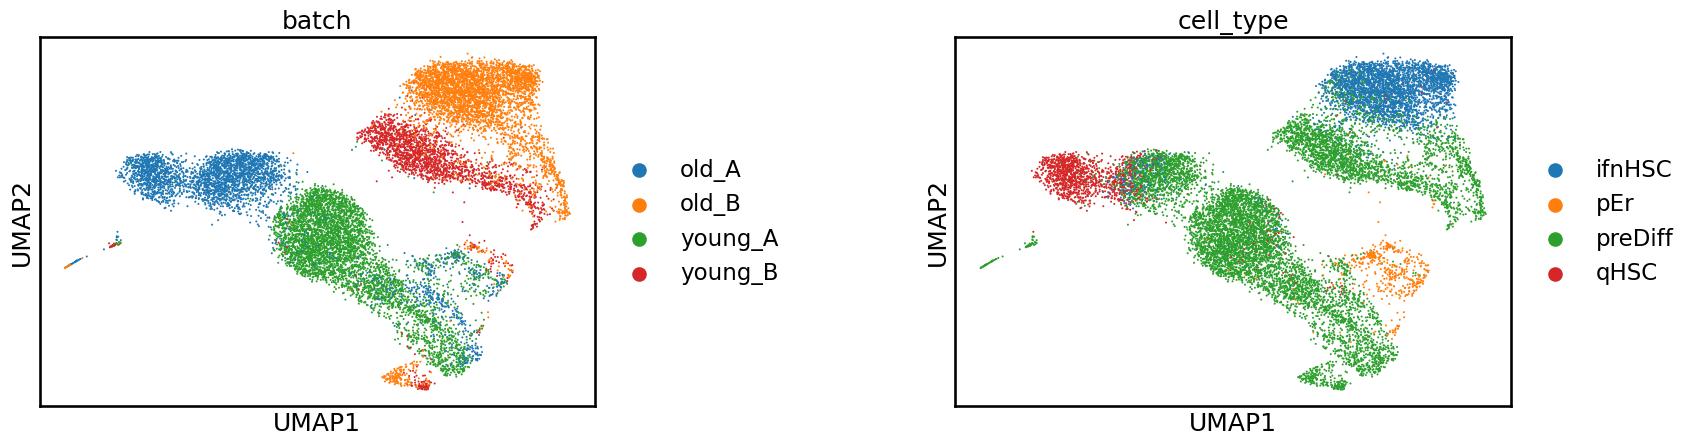

In [6]:
sc.pl.umap(adata_unintegrated, color=[BATCH_KEY, LABEL_KEY], wspace=0.5)

## Integracja (scib.ig)

Odpalamy `scanorama` i `harmony` — obie zapisują embedding do `obsm['X_emb']`, więc jedna pętla wystarcza. `sc.pp.neighbors(..., use_rep="X_emb")` jest tu wymagane: `graph_conn_` w benchmarku liczy się z grafu sąsiedztwa na `adata_int`, nie z samego embeddingu. Pozostałe metody scIB (`combat`/`mnn` bez embeddingu, `bbknn` tylko z grafem i konfliktem wersji sklearn, `scvi` wymagający `layers['counts']`) są odłożone — patrz TODO w `docs/data_integration_notebook_788cc68f.plan.md`.

In [7]:
%%time
results = {}
for method in METHODS:
    adata_int = getattr(scib.ig, method)(adata_hvg.copy(), batch=BATCH_KEY)
    sc.pp.neighbors(adata_int, use_rep="X_emb")
    sc.tl.umap(adata_int)
    results[method] = adata_int
    print(f"{method}: OK ({adata_int.n_obs} komórek, X_emb {adata_int.obsm['X_emb'].shape})")

Found 2000 genes among all datasets


[[0.        0.0003125 0.        0.       ]
 [0.        0.        0.        0.       ]
 [0.        0.        0.        0.       ]
 [0.        0.        0.        0.       ]]


/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/utils.py:72: FutureWarning: The method concatenate is deprecated and will be removed in the future. Use anndata.concat instead of AnnData.concatenate. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  return anndata.AnnData.concatenate(*adata_list, **kwargs)


scanorama: OK (14100 komórek, X_emb (14100, 100))


	Initialization is completed.


	Completed 1 / 10 iteration(s).


	Completed 2 / 10 iteration(s).


	Completed 3 / 10 iteration(s).
Reach convergence after 3 iteration(s).


harmony: OK (14100 komórek, X_emb (14100, 50))
CPU times: user 35.1 s, sys: 5.48 s, total: 40.6 s
Wall time: 26.6 s


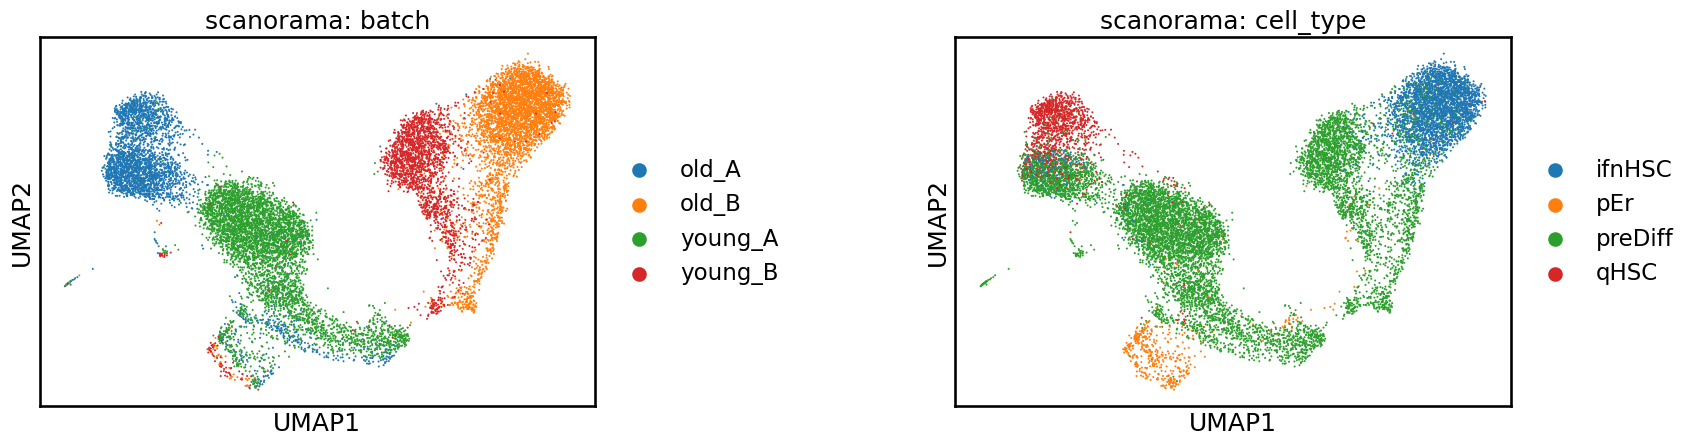

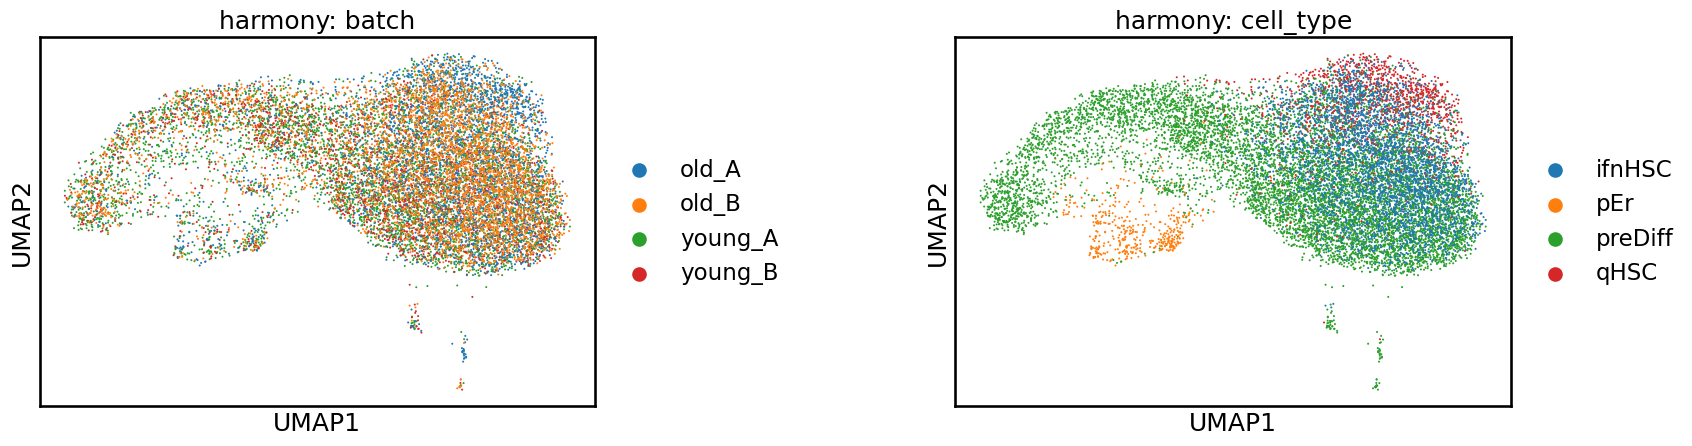

In [8]:
for method, adata_int in results.items():
    sc.pl.umap(
        adata_int, color=[BATCH_KEY, LABEL_KEY], wspace=0.5,
        title=[f"{method}: {BATCH_KEY}", f"{method}: {LABEL_KEY}"],
    )

## Benchmark (scib.metrics.metrics_fast)

Metryki liczymy z jawnym `embed="X_emb"` — domyślnie `metrics_fast` czyta `X_pca`, którego żadna z tych dwóch metod nie ustawia.

In [9]:
%%time
metrics_rows = {}
for method, adata_int in results.items():
    metrics_rows[method] = scib.metrics.metrics_fast(
        adata_unintegrated, adata_int, BATCH_KEY, LABEL_KEY, embed="X_emb",
    ).iloc[:, 0]

metrics_df = pd.DataFrame(metrics_rows).T
metrics_df.to_csv(OUTDIR / "integration_metrics.csv")
metrics_df

Silhouette score...


PC regression...
Variance contribution increased after integration!
Setting PCR comparison score to 0.
Isolated labels ASW...


/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/metrics/isolated_labels.py:311: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  batch_per_lab = tmp.groupby(label_key).agg({batch_key: "count"})
/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/metrics/isolated_labels.py:186: UserWarning: iso_threshold is equal to number of batches in data, no isolated labels will be foun

Graph connectivity...


/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/metrics/graph_connectivity.py:56: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  tab = pd.value_counts(labels)
/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/metrics/graph_connectivity.py:56: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  tab = pd.value_counts(labels)
/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/metrics/graph_connectivity.py:56: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  tab = pd.value_counts(labels)
/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/metrics/graph_connectivity.py:56: FutureWarning: pandas.value_counts is deprecated and will be removed in a fut

/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/metrics/highly_variable_genes.py:35: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  hvg_dir[i.obs[batch][0]] = i.var.index[hvg["highly_variable"]]
/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/metrics/highly_variable_genes.py:35: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  hvg_dir[i.obs[batch][0]] = i.var.index[hvg["highly_variable"]]
/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/metrics/highly_variable_genes.py:35: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. 

... (6 outputs left out)

/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/metrics/highly_variable_genes.py:35: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  hvg_dir[i.obs[batch][0]] = i.var.index[hvg["highly_variable"]]
/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/metrics/highly_variable_genes.py:35: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  hvg_dir[i.obs[batch][0]] = i.var.index[hvg["highly_variable"]]
/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/metrics/highly_variable_genes.py:35: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. 

CPU times: user 18.8 s, sys: 5.09 s, total: 23.9 s
Wall time: 13.5 s


/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/metrics/highly_variable_genes.py:76: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  batch_var = ad_post.obs[batch_key][0]
/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/metrics/highly_variable_genes.py:76: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  batch_var = ad_post.obs[batch_key][0]
/Users/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/metrics/highly_variable_genes.py:76: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be t

,NMI_cluster/label,ARI_cluster/label,ASW_label,ASW_label/batch,PCR_batch,cell_cycle_conservation,isolated_label_F1,isolated_label_silhouette,graph_conn,kBET,iLISI,cLISI,hvg_overlap,trajectory
scanorama,NaN,NaN,0.516707,0.938751,0.000000,NaN,NaN,NaN,0.991914,NaN,NaN,NaN,0.8805,NaN
harmony,NaN,NaN,0.477289,0.960487,0.939899,NaN,NaN,NaN,0.971927,NaN,NaN,NaN,1.0000,NaN


## Poprawiona macierz ekspresji + regresja cyklu komórkowego (odpowiednik R `ScaleData`)

Sekcja **Integracja (scib.ig)** wyżej daje tylko *embedding* (`obsm['X_emb']`) — to wystarcza dla `scib.metrics`, ale nie odtwarza kroku z oryginalnego pipeline'u R (`scHSC_herault/R_src/Seurat3_integration.R:148`: `ScaleData(vars.to.regress = "G2M_score+S_score+G1_score")` na *macierzy ekspresji* po integracji — patrz `docs/scHSC_herault_cell_cycle_i_standaryzacja.md`).

**Harmony nie ma tu odpowiednika** — koryguje wyłącznie embedding w przestrzeni PCA (`Z_corr`), nigdy nie dotyka macierzy ekspresji.

**Scanoramy też nie używamy do tego kroku** (mimo że `scanorama.correct_scanpy` z pozoru zwraca poprawioną macierz ekspresji `.X`) — sprawdziłem w źródle `scanorama.scanorama.process_data()`, że wewnątrz `correct()` dane są w miejscu L2-znormalizowane per komórka (`datasets[i] = normalize(ds, axis=1)`, mutacja listy przekazanej przez referencję) **przed** liczeniem korekty batcha. Zweryfikowałem to też empirycznie: log-normalizowane dane mają zakres `0.0–9.1`, a wynik `scanorama.correct_scanpy` na tych samych komórkach/genach — `-0.046–0.541`. To nie jest już ta sama skala co Seuratowe `data`/`scale.data` (log-normalizowana ekspresja genu niezależna od pozostałych genów w komórce) — L2-normalizacja per komórka sprawia, że wartość genu zależy od tego, ile i jak silnie inne geny są wyrażone w tej samej komórce. Regresja liniowa cyklu komórkowego na takich danych miałaby inne znaczenie niż w R. Więcej w `docs/scHSC_herault_cell_cycle_i_standaryzacja.md` (sekcja 4).

**Zamiast tego: `scanpy.pp.combat`** — klasyczna, empiryczno-bayesowska korekta batcha (Johnson et al. 2007) działająca *w tej samej skali* co dane wejściowe (log-normalizowane), bez żadnej ukrytej renormalizacji. To słabszy algorytm niż Seuratowa CCA/scanorama (liniowy, nie łapie nieliniowych efektów batcha), ale zachowuje semantykę wartości genu — dzięki czemu kolejny krok (liniowa regresja cyklu komórkowego) komponuje się z nim w sposób analogiczny do R.

Regresja cyklu komórkowego (komórka niżej) dołącza `G1_score`/`S_score`/`G2M_score` z `cell_cycle_scores.tsv` (policzone przez `scran::cyclone` w `1. Cell Cycle Classification.ipynb`) i odtwarza `ScaleData(vars.to.regress=...)` przez `scanpy.pp.regress_out` + `scanpy.pp.scale(max_value=10)`.

Wynikowa `adata_combat_corrected.X` (batch-corrected przez ComBat **i** cell-cycle-regressed, na tym samym kanonicznym zestawie HVG co reszta pipeline'u — `dataset_hvgs.csv`) to macierz, na której `3. Final Cell Annotation.ipynb` ma liczyć PCA + Leiden (ostateczne klastry), podczas gdy binaryzacja scBoolSeq + dopasowanie markerowe w tamtym notebooku zostaje na surowych, nieskorygowanych danych (scBoolSeq wymaga prawdziwego zera dropout — regresja/korekta batcha by je zniszczyła, sprawdzone empirycznie na genie `Aif1`: 98.1% komórek z dokładnym `0.0` przed regresją → 9419 różnych wartości po `regress_out`).

In [ ]:
adata_combat_corrected = adata_hvg.copy()
sc.pp.combat(adata_combat_corrected, key=BATCH_KEY)
adata_combat_corrected.layers["lognorm"] = adata_hvg.X.copy()
adata_combat_corrected

In [ ]:
CELL_CYCLE_SCORES_TSV = Path("cell_cycle_scores.tsv")

cc_scores = pd.read_csv(CELL_CYCLE_SCORES_TSV, sep="\t", index_col=0)
missing_cc = adata_combat_corrected.obs_names.difference(cc_scores.index)
assert missing_cc.empty, f"{len(missing_cc)} komórek bez wyniku cyclone w {CELL_CYCLE_SCORES_TSV}"

for col in ["G1_score", "S_score", "G2M_score"]:
    adata_combat_corrected.obs[col] = cc_scores.loc[adata_combat_corrected.obs_names, col].to_numpy()

# R_src/Seurat3_integration.R:148 -> ScaleData(vars.to.regress="G2M_score+S_score+G1_score")
sc.pp.regress_out(adata_combat_corrected, ["G1_score", "S_score", "G2M_score"])
sc.pp.scale(adata_combat_corrected, max_value=10)

## Export

Zapisujemy zintegrowane `.h5ad` per metoda (embedding w `obsm['X_emb']`, etykiety w `obs['cell_type']`) pod trajectory inference, tabelę metryk i podsumowanie runu.

In [ ]:
for method, adata_int in results.items():
    adata_int.write_h5ad(OUTDIR / f"integrated_{method}.h5ad")

adata_combat_corrected.write_h5ad(OUTDIR / "integrated_combat_corrected_expression.h5ad")

summary = {
    "input_h5ad": str(INPUT_H5AD),
    "metadata_tsv": str(METADATA_TSV),
    "batch_key": BATCH_KEY,
    "label_key": LABEL_KEY,
    "methods": METHODS,
    "n_cells_before_discard_filter": int(n_before),
    "n_cells_after_discard_filter": int(adata.n_obs),
    "n_hvg": int(len(hvg_genes)),
    "cell_cycle_scores_tsv": str(CELL_CYCLE_SCORES_TSV),
}
with open(OUTDIR / "integration_run_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

summary